In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import shap
from plotly.subplots import make_subplots
import warnings

In [2]:
warnings.filterwarnings("ignore")

In [3]:
df_customers = pd.read_csv("ecommerce_churn_data.csv")

## Preliminary data analysis

In [4]:
df_customers.head()

,CustomerID,Age,Gender,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,HoursSpentOnApp,NumberOfDevicesRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder,CashbackAmount,Churn
0,56346,29,Male,5.0,Desktop,1,7.2,2.5,2,3,1,1,8,15,45.2,1
1,56347,45,Female,36.0,Mobile,3,20.1,4.8,4,5,3,0,50,2,320.5,0
2,56348,22,Male,2.0,Mobile,1,5.0,1.8,1,2,1,1,3,25,10.1,1
3,56349,39,Female,24.0,Desktop,2,15.3,3.9,3,4,2,0,35,5,210.9,0
4,56350,31,Male,12.0,Mobile,1,8.8,3.0,2,3,1,0,18,10,80.4,0


In [5]:
df_customers.tail()

,CustomerID,Age,Gender,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,HoursSpentOnApp,NumberOfDevicesRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder,CashbackAmount,Churn
10200,9946,32,Female,25.0,Mobile,2,8.0,4.1,3,4,1,0,27,7,240.00,0
10201,9947,26,Male,9.0,Mobile,3,4.7,3.3,1,3,1,0,9,15,105.75,0
10202,9948,42,Female,35.0,Desktop,1,11.5,4.5,4,5,3,0,30,4,270.00,0
10203,9949,31,Male,16.0,Mobile,2,6.0,3.5,2,3,2,1,18,11,160.50,1
10204,9950,28,Female,3.0,Mobile,3,3.2,2.2,1,2,1,0,4,30,55.00,0


In [6]:
df_customers.shape

(10205, 16)

In [7]:
df_customers.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'PreferredLoginDevice',
       'CityTier', 'WarehouseToHome', 'HoursSpentOnApp',
       'NumberOfDevicesRegistered', 'SatisfactionScore', 'NumberOfAddress',
       'Complain', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount',
       'Churn'],
      dtype='object')

In [8]:
df_customers.dtypes

CustomerID                     int64
Age                            int64
Gender                        object
Tenure                       float64
PreferredLoginDevice          object
CityTier                       int64
WarehouseToHome              float64
HoursSpentOnApp              float64
NumberOfDevicesRegistered      int64
SatisfactionScore              int64
NumberOfAddress                int64
Complain                       int64
OrderCount                     int64
DaySinceLastOrder              int64
CashbackAmount               float64
Churn                          int64
dtype: object

In [9]:
df_customers.nunique()

CustomerID                   5751
Age                            47
Gender                          3
Tenure                         77
PreferredLoginDevice            2
CityTier                        3
WarehouseToHome               244
HoursSpentOnApp                71
NumberOfDevicesRegistered       5
SatisfactionScore               5
NumberOfAddress                 5
Complain                        2
OrderCount                    115
DaySinceLastOrder              47
CashbackAmount               1073
Churn                           2
dtype: int64

In [10]:
df_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10205 entries, 0 to 10204
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 10205 non-null  int64  
 1   Age                        10205 non-null  int64  
 2   Gender                     10205 non-null  object 
 3   Tenure                     10204 non-null  float64
 4   PreferredLoginDevice       10205 non-null  object 
 5   CityTier                   10205 non-null  int64  
 6   WarehouseToHome            10205 non-null  float64
 7   HoursSpentOnApp            10205 non-null  float64
 8   NumberOfDevicesRegistered  10205 non-null  int64  
 9   SatisfactionScore          10205 non-null  int64  
 10  NumberOfAddress            10205 non-null  int64  
 11  Complain                   10205 non-null  int64  
 12  OrderCount                 10205 non-null  int64  
 13  DaySinceLastOrder          10205 non-null  int

In [11]:
df_customers.describe()

,CustomerID,Age,Tenure,CityTier,WarehouseToHome,HoursSpentOnApp,NumberOfDevicesRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder,CashbackAmount,Churn
count,10205.000000,10205.000000,10204.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000,10205.000000
mean,29677.581872,35.193043,19.685515,2.007349,9.887428,3.343626,2.833807,3.504459,1.861832,0.216267,21.453895,8.891720,157.953214,0.238707
std,25617.824693,9.625432,14.475853,0.826741,5.481747,1.133353,0.921249,1.162892,0.920454,0.411718,18.955878,8.283807,107.627670,0.426314
min,307.000000,18.000000,1.000000,1.000000,0.500000,0.800000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5097.000000,28.000000,8.000000,1.000000,6.000000,2.500000,2.000000,3.000000,1.000000,0.000000,9.000000,3.000000,75.000000,0.000000
50%,9711.000000,33.000000,16.000000,2.000000,9.000000,3.400000,3.000000,4.000000,2.000000,0.000000,18.000000,6.000000,140.000000,0.000000
75%,56429.000000,42.000000,28.000000,3.000000,13.000000,4.100000,3.000000,4.000000,2.000000,0.000000,28.000000,12.000000,220.000000,0.000000
max,56760.000000,65.000000,85.000000,3.000000,35.000000,8.500000,5.000000,5.000000,5.000000,1.000000,250.000000,60.000000,1120.000000,1.000000


## Data Cleaning
- Handeling Missing Values
- Handeling duplicate samples
- Handeling duplicate columns
- Changing column data types
- Removing unnecessary columns

In [12]:
df_customers = df_customers.fillna(0)

In [13]:
col_name = ["CityTier", "NumberOfDevicesRegistered", "SatisfactionScore", "NumberOfAddress", "Complain", "Churn"]

In [14]:
df_customers[col_name] = df_customers[col_name].astype("object")

In [15]:
df_customers.drop(columns=df_customers[["CustomerID", "Complain"]], inplace=True)

In [16]:
df_customers.isnull().sum()

Age                          0
Gender                       0
Tenure                       0
PreferredLoginDevice         0
CityTier                     0
WarehouseToHome              0
HoursSpentOnApp              0
NumberOfDevicesRegistered    0
SatisfactionScore            0
NumberOfAddress              0
OrderCount                   0
DaySinceLastOrder            0
CashbackAmount               0
Churn                        0
dtype: int64

In [17]:
df_customers.duplicated().sum()

np.int64(3457)

In [18]:
duplicated_columns = df_customers.T.duplicated()
df_customers.columns[duplicated_columns]

Index([], dtype='object')

In [19]:
df_customers.drop_duplicates(inplace=True)

In [20]:
numeric_features = df_customers.select_dtypes(["int64", "float64"])

In [21]:
category_features = df_customers.select_dtypes("object")

## Descriptive Analysis
1 .**Outlier Detection**
- Robust Z-score

2 .**Moments**
- Mean, Median
- Variance, STD
- Skewness
- Kurtesis

3 .**Visuallization**
- Histogram KDE
- Correlation Heatmap
- Pairplot

In [22]:
moments = {}
for cols in numeric_features:
    moments[cols] = [numeric_features[cols].mean(), numeric_features[cols].median(), numeric_features[cols].var(), numeric_features[cols].std(),
                    numeric_features[cols].skew(), numeric_features[cols].kurt()]

moments = pd.DataFrame(moments)
moments[" "] = ["Mean", "Medain", "Variance", "Std", "Skewness", "Kurtosis"]
moments = moments.set_index(" ")
moments

,Age,Tenure,WarehouseToHome,HoursSpentOnApp,OrderCount,DaySinceLastOrder,CashbackAmount
,,,,,,,
Mean,35.399229,19.673829,10.131076,3.330735,21.774155,8.600030,158.893391
Medain,34.000000,16.000000,9.000000,3.300000,18.000000,6.000000,140.000000
Variance,94.739659,215.046554,31.131883,1.366395,372.560518,63.200160,12366.873639
Std,9.733430,14.664466,5.579595,1.168929,19.301827,7.949853,111.206446
Skewness,0.455166,1.026299,0.984656,0.276534,3.196916,1.718598,1.363785
Kurtosis,-0.779473,0.786935,0.954729,-0.017980,20.365795,3.416222,3.945660


In [23]:
def robust_zscore(data=None, columns=None):
    medians = np.median(data[columns], axis=0)
    MAD = np.median(np.abs(data[columns] - medians), axis=0)
    mi = (0.6745 * (data[columns] - medians)) / MAD

    z_threshold = 3

    outlier_detect = np.array(np.abs(mi) > z_threshold)

    outlier_indices = data[columns].index[outlier_detect.any(axis=1)]
    return outlier_indices

In [24]:
robust_zscore(data=df_customers, columns=numeric_features.columns)

Index([    2,    11,    12,    15,    25,    26,    37,    38,    42,    52,
       ...
        9752,  9755,  9759,  9802,  9808,  9814,  9820,  9826,  9832, 10054],
      dtype='int64', length=948)

In [25]:
numeric_features["Churn"] = df_customers["Churn"]

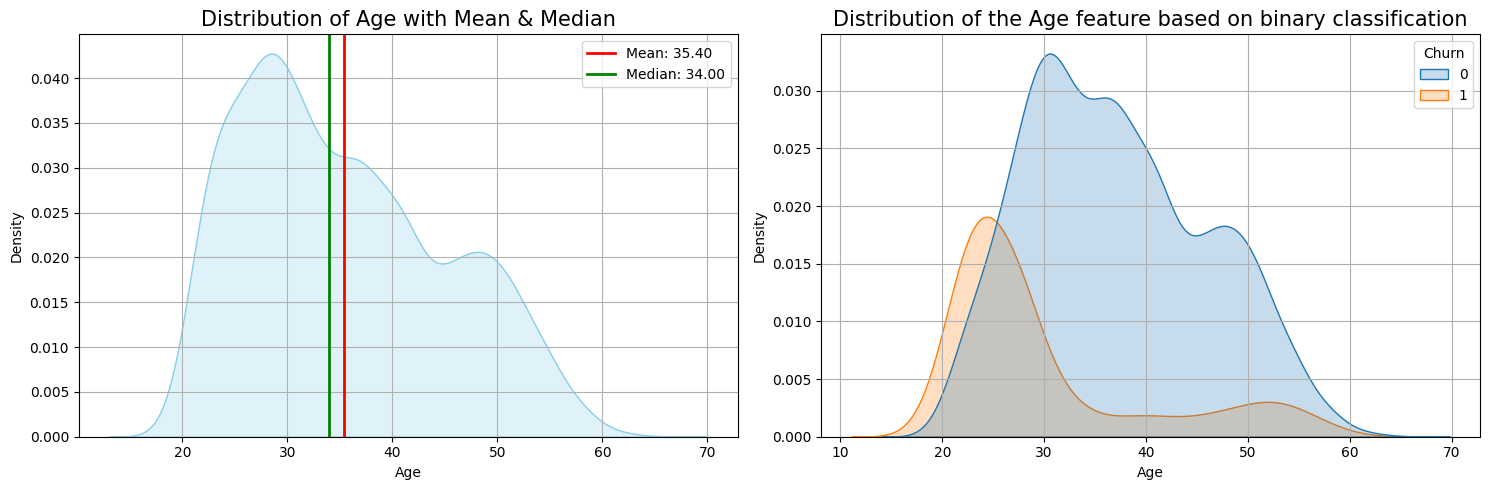

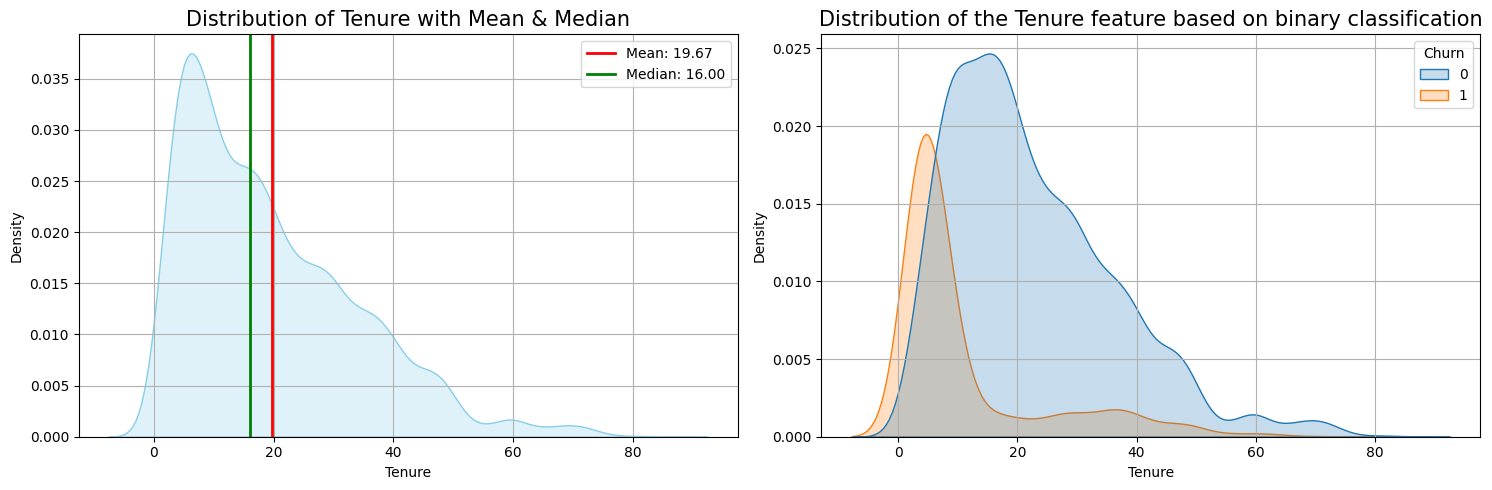

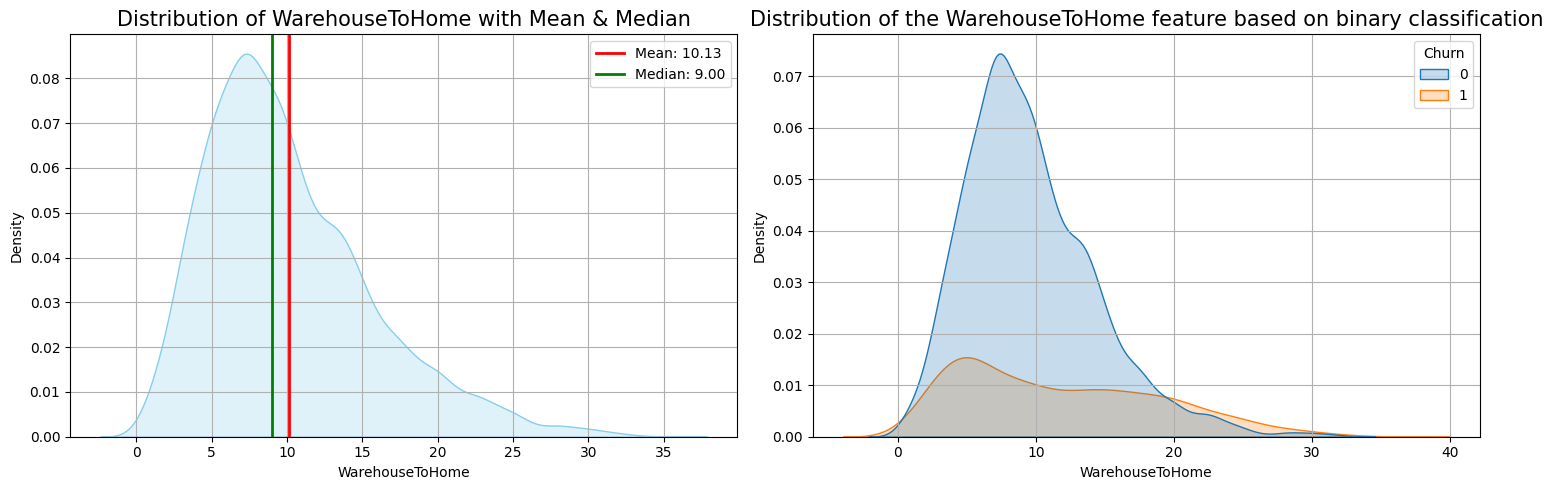

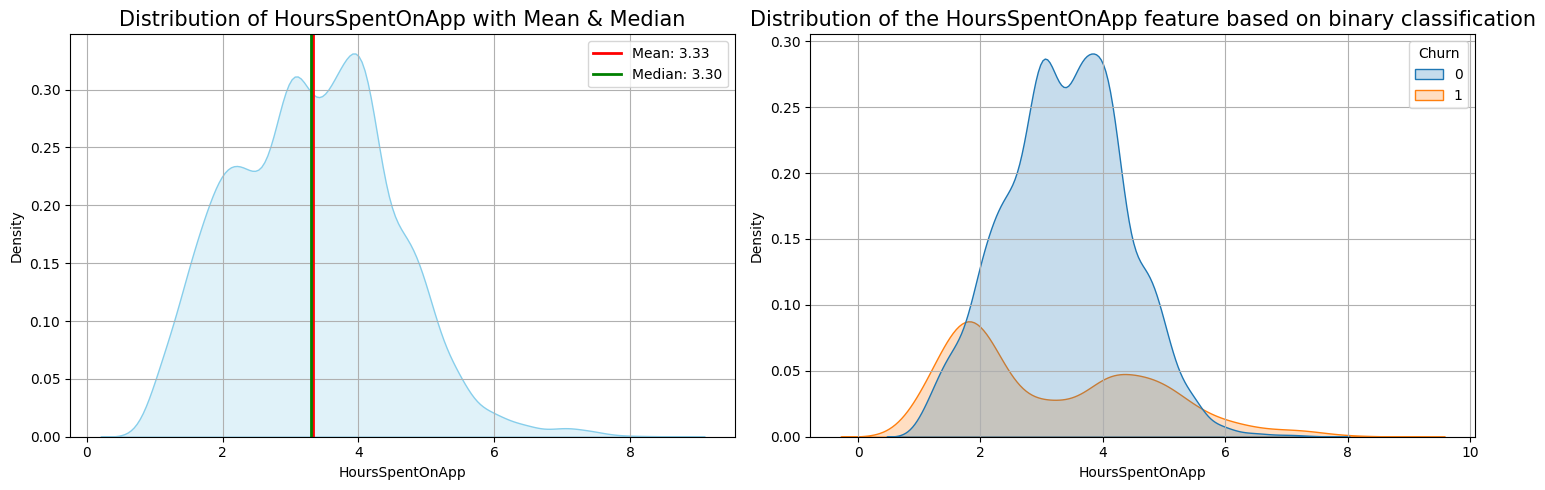

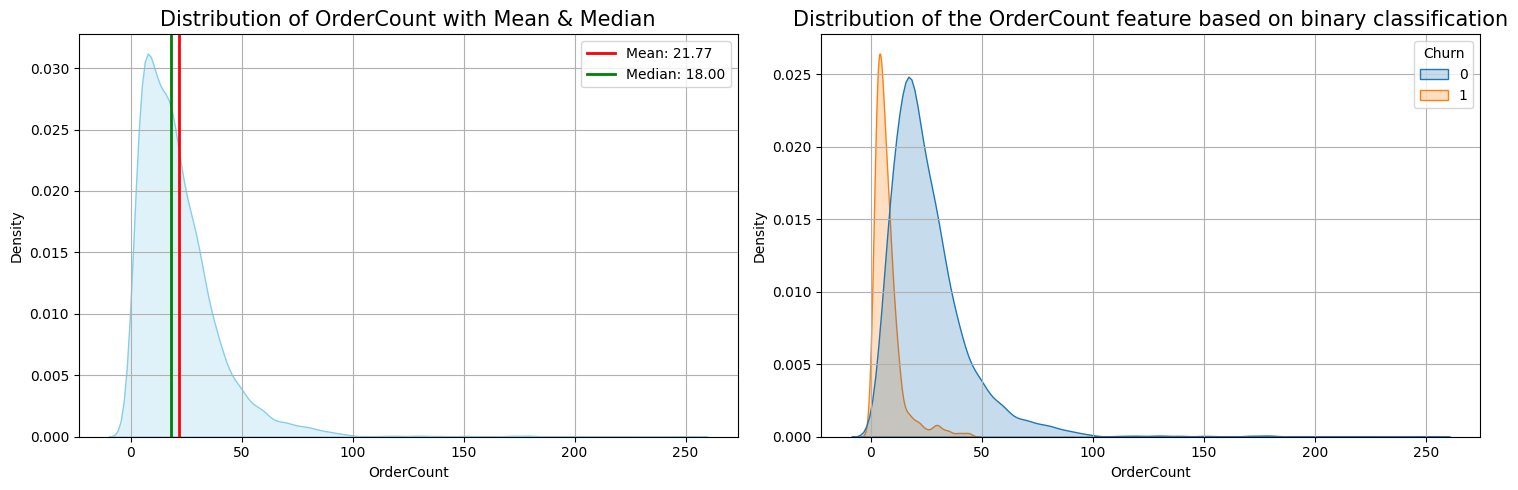

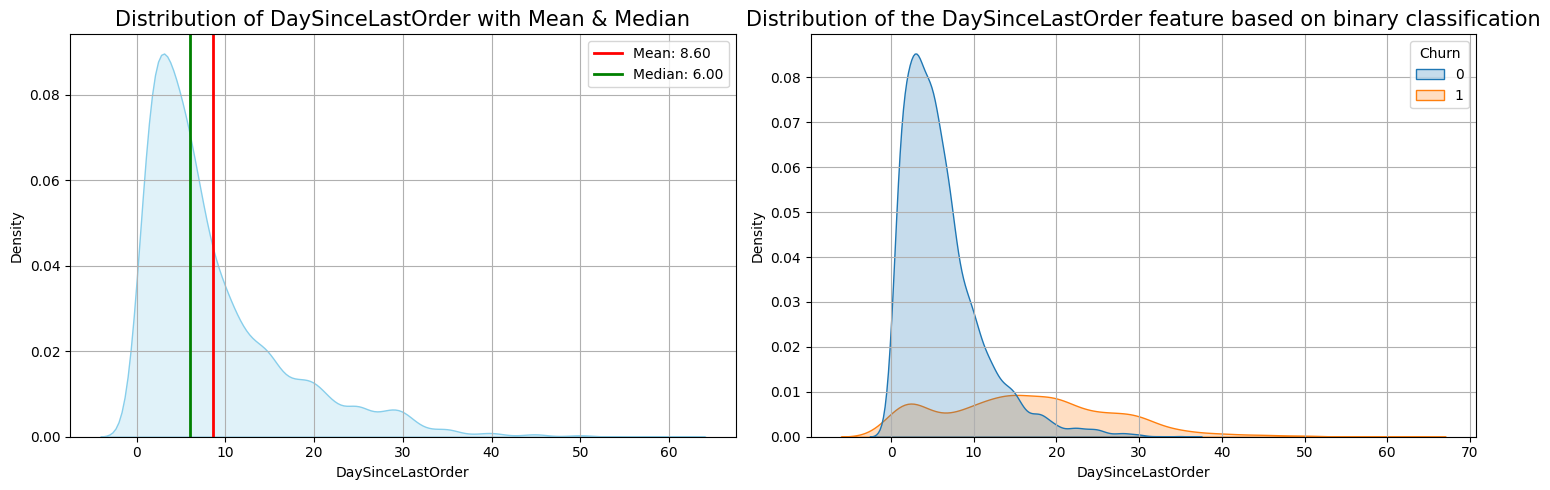

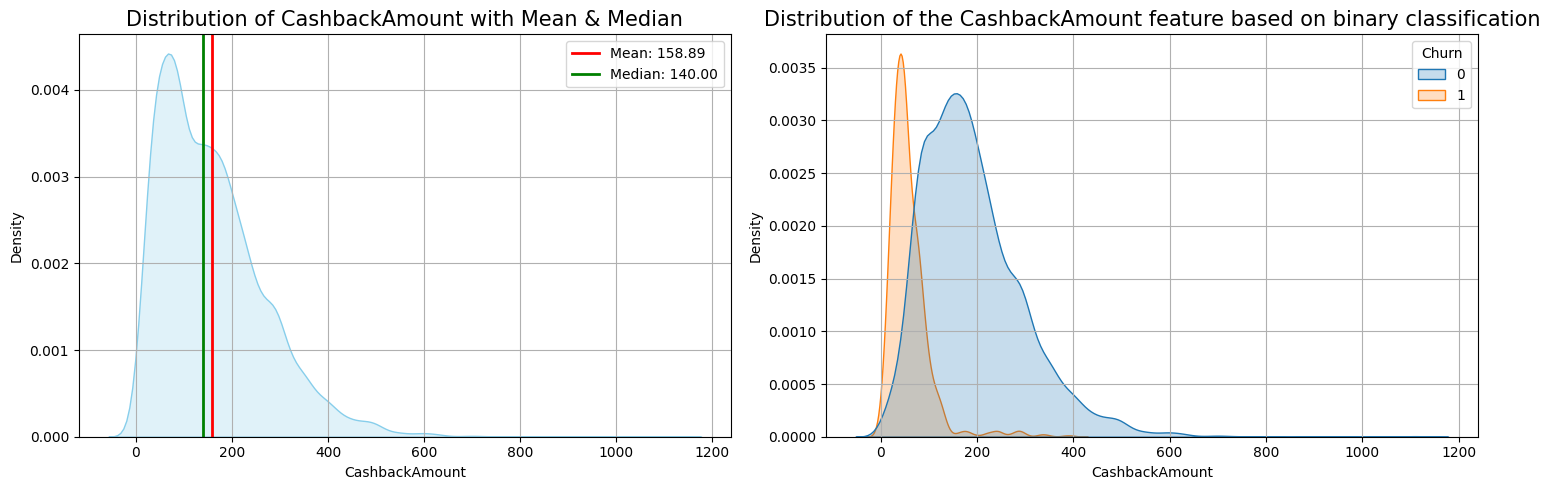

In [26]:
for column in numeric_features:
    if column == "Churn":
        continue

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.kdeplot(data=numeric_features, x=column, color='skyblue', fill=True, ax=axes[0])
    
    mean_val = numeric_features[column].mean()
    median_val = numeric_features[column].median()

    axes[0].axvline(mean_val, color='red', linewidth=2, label=f'Mean: {mean_val:.2f}')
    axes[0].axvline(median_val, color='green', linewidth=2, label=f'Median: {median_val:.2f}')
    
    axes[0].set_title(f'Distribution of {column} with Mean & Median', fontsize=15)
    axes[0].legend()
    axes[0].grid()

    sns.kdeplot(data=numeric_features, x=column, color='skyblue', fill=True, hue="Churn", ax=axes[1])
    axes[1].set_title(f'Distribution of the {column} feature based on binary classification', fontsize=15)
    axes[1].grid()
    
    plt.tight_layout()
    plt.show()

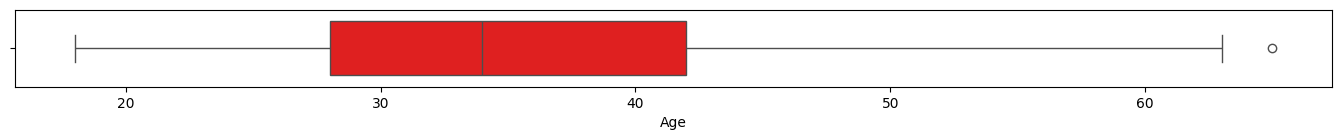

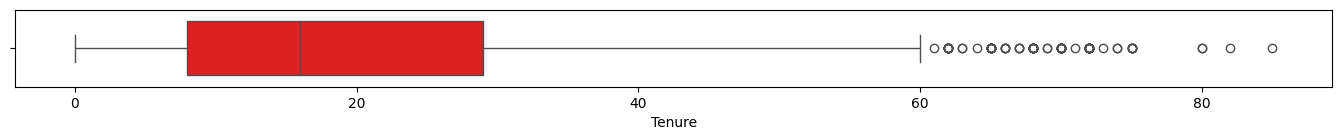

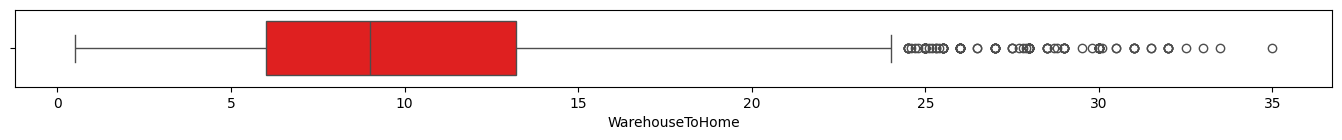

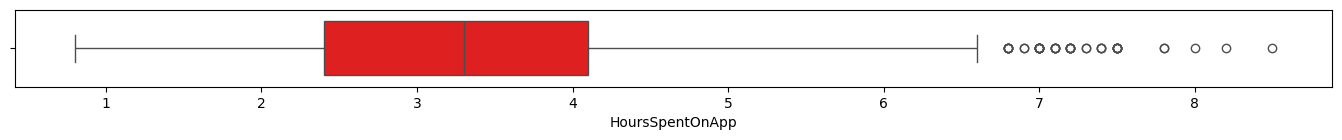

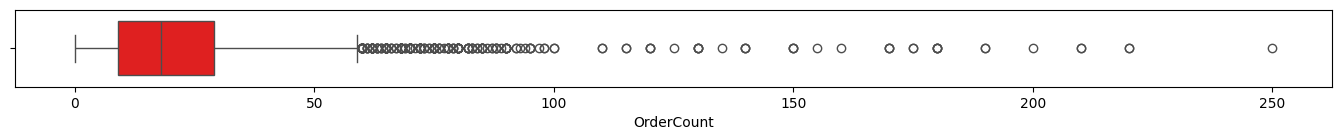

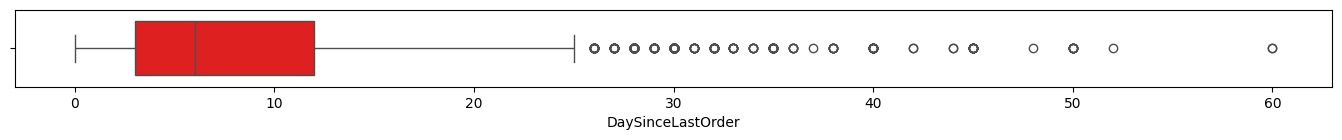

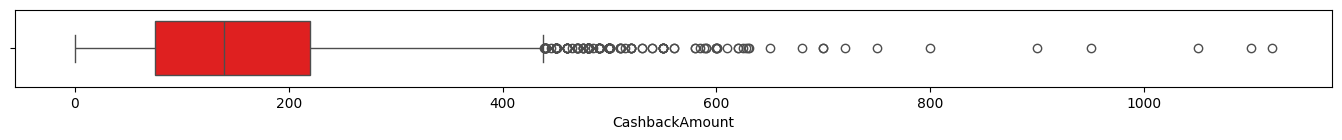

In [27]:
for column in numeric_features:
    if column == "Churn":
        continue
    plt.figure(figsize=(17, 1))
    sns.boxplot(x=df_customers[column], color='red', orient='h', width=0.7)
    plt.show()

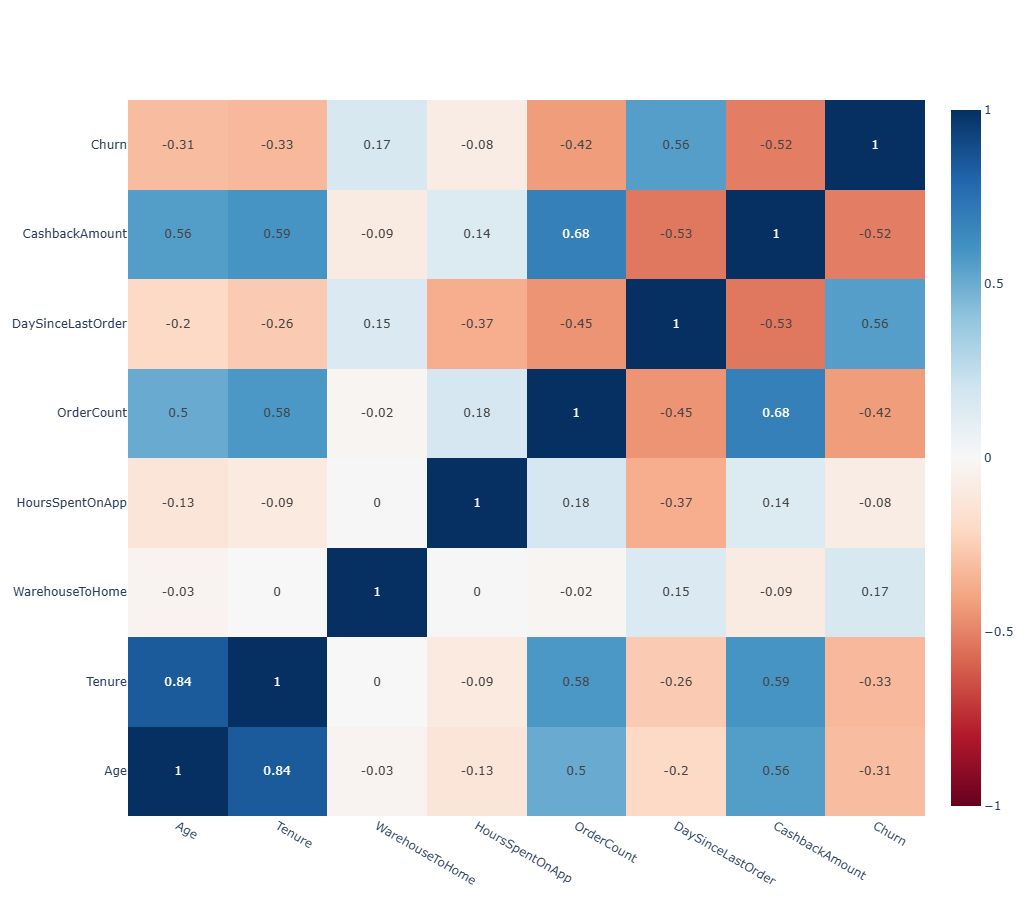

In [28]:
corr_matrix = numeric_features.corr()

fig = go.Figure(data=go.Heatmap(
    z=corr_matrix.values,
    x=corr_matrix.columns,
    y=corr_matrix.columns,
    colorscale='RdBu',
    zmin=-1, zmax=1,
    text=corr_matrix.values.round(2),
    texttemplate="%{text}",
))

fig.update_layout(
    width=900,
    height=900,
    xaxis_nticks=36,
    template='plotly_white'
)

fig.show()

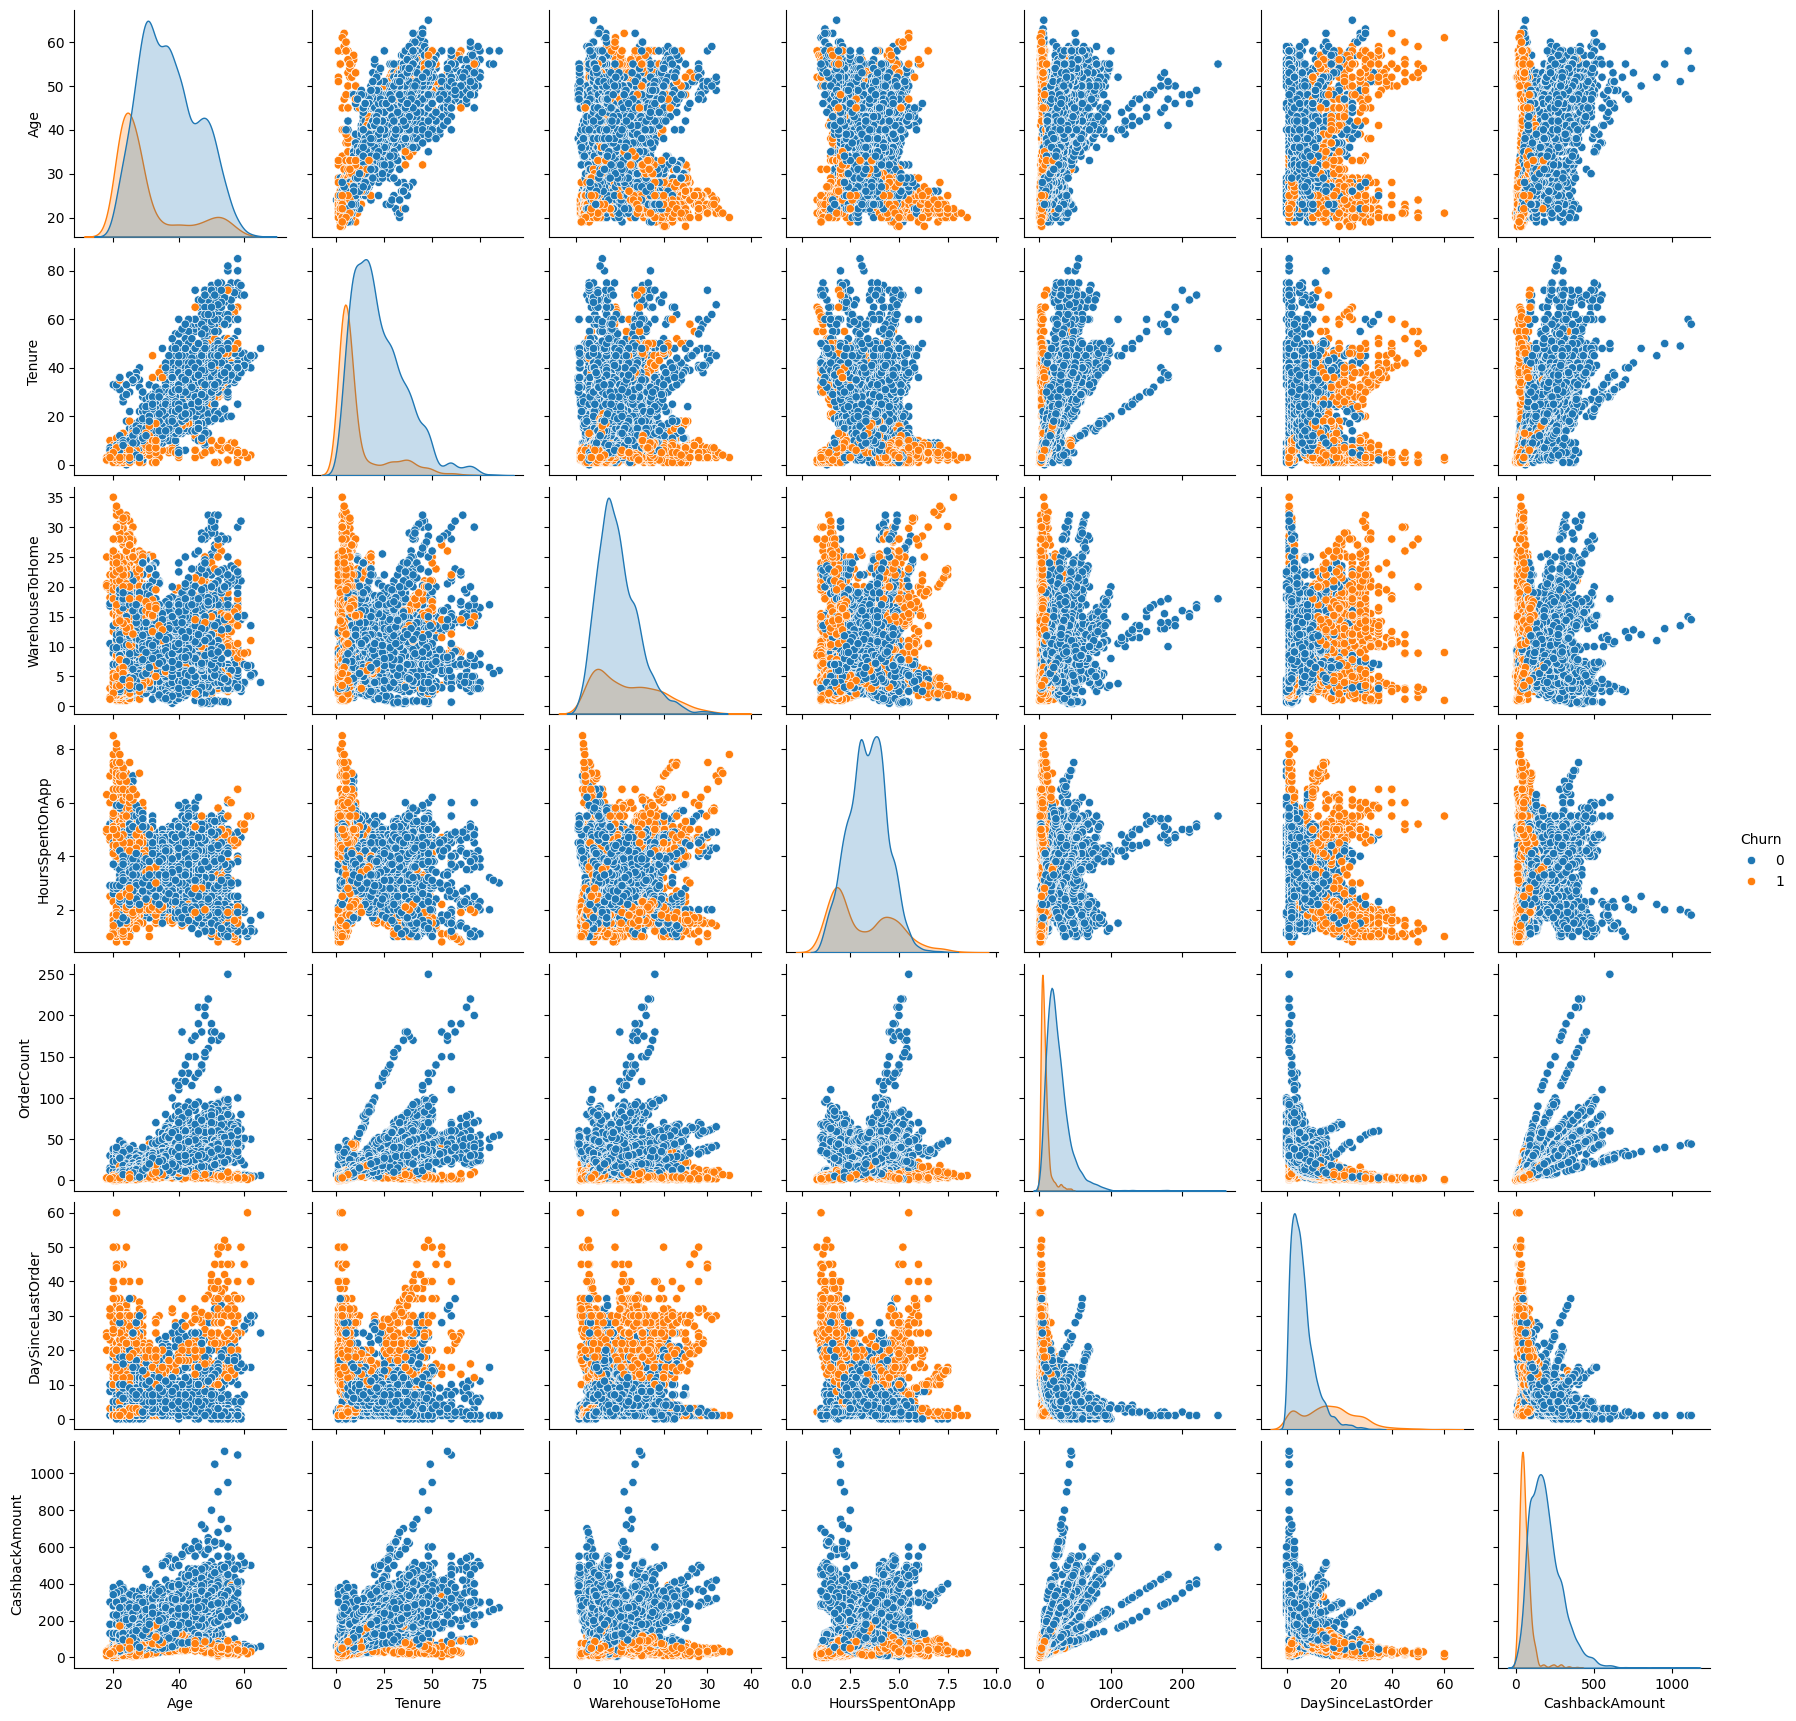

In [29]:
sns.pairplot(data=numeric_features, hue="Churn")
plt.show()

## Categorical Analysis
1 .**Visualization of categorical feature distributions**
- Countplot & Stacked Bar Plot
- Treemap

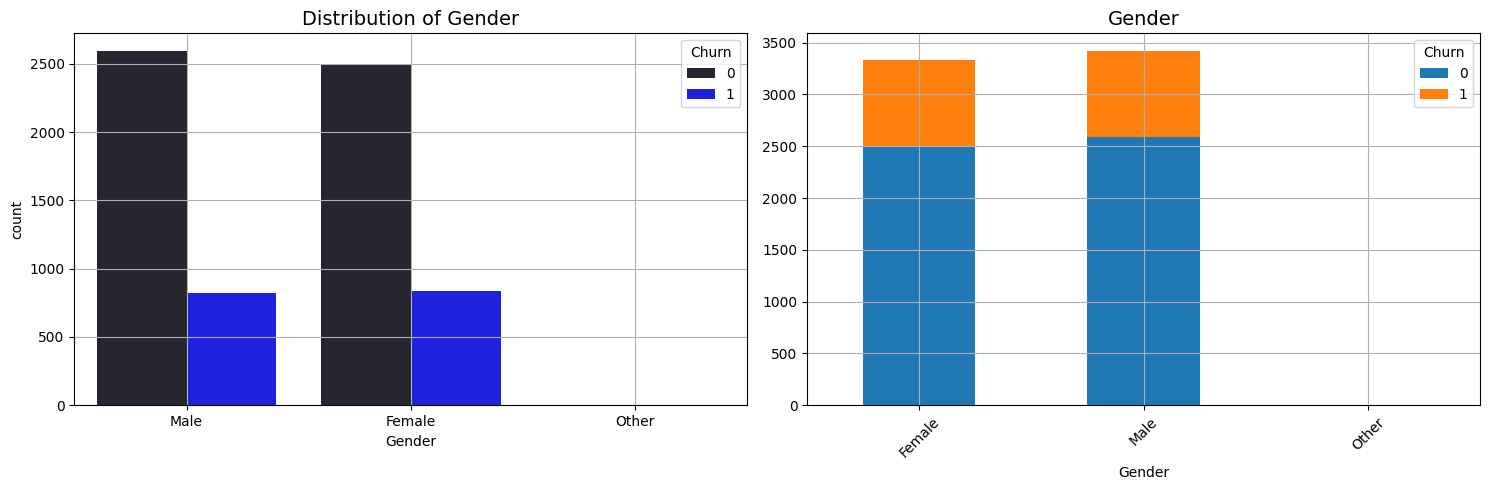

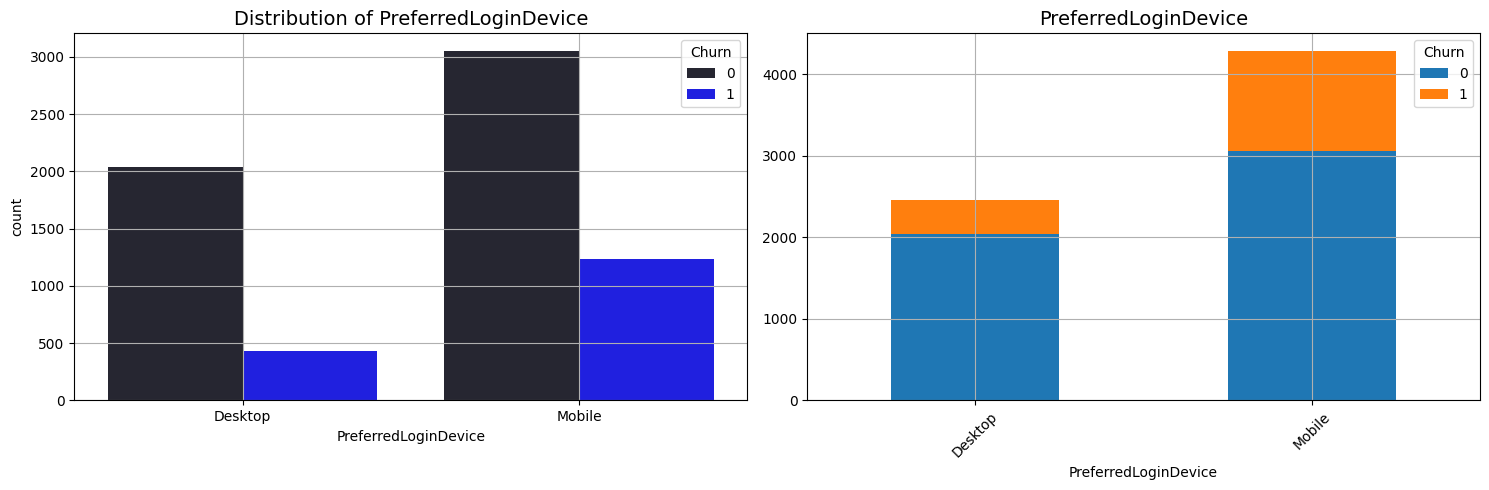

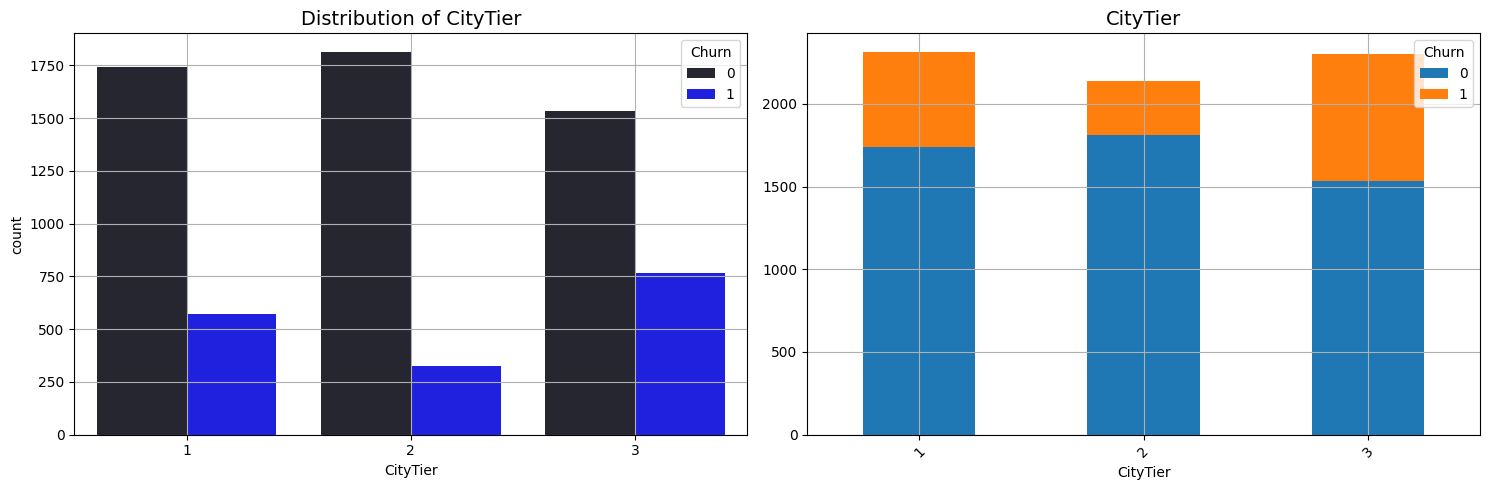

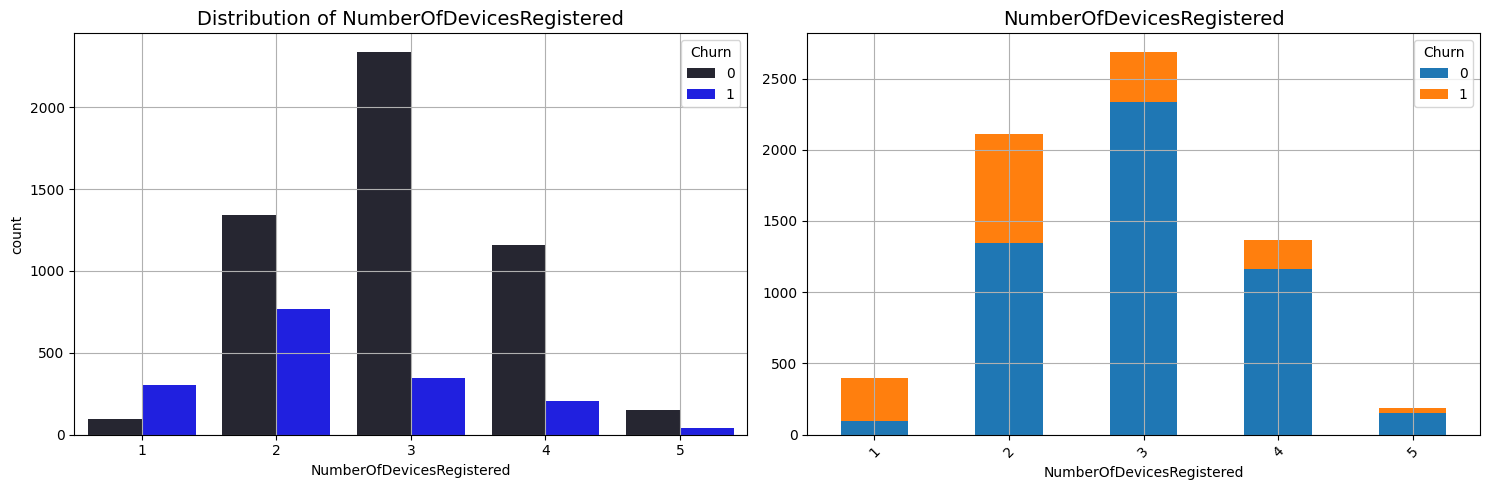

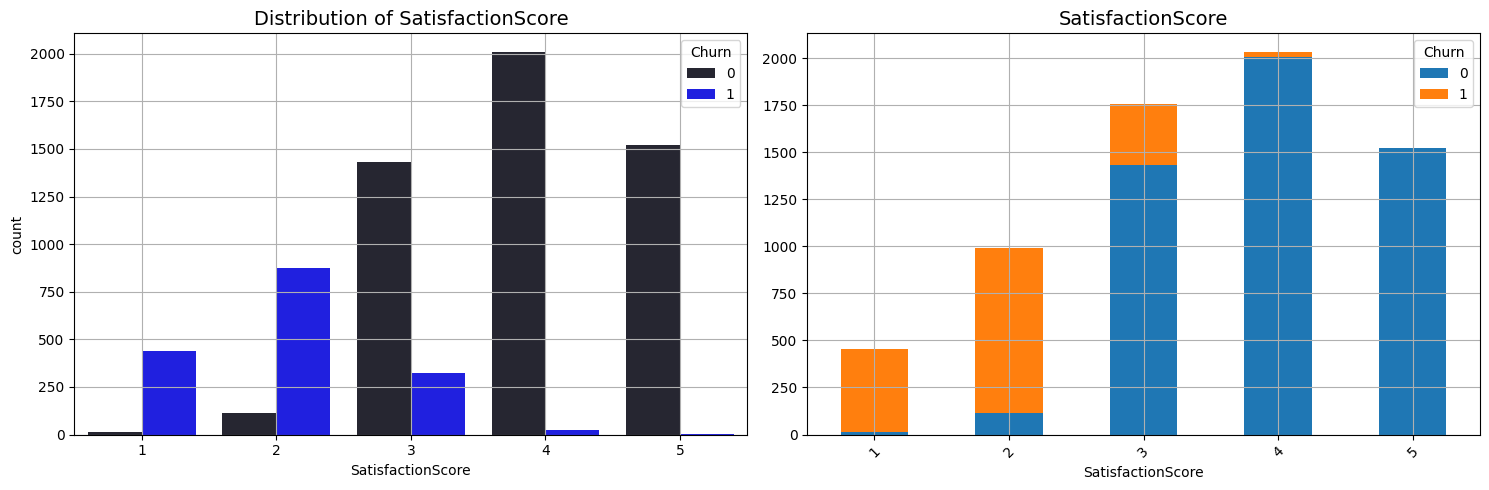

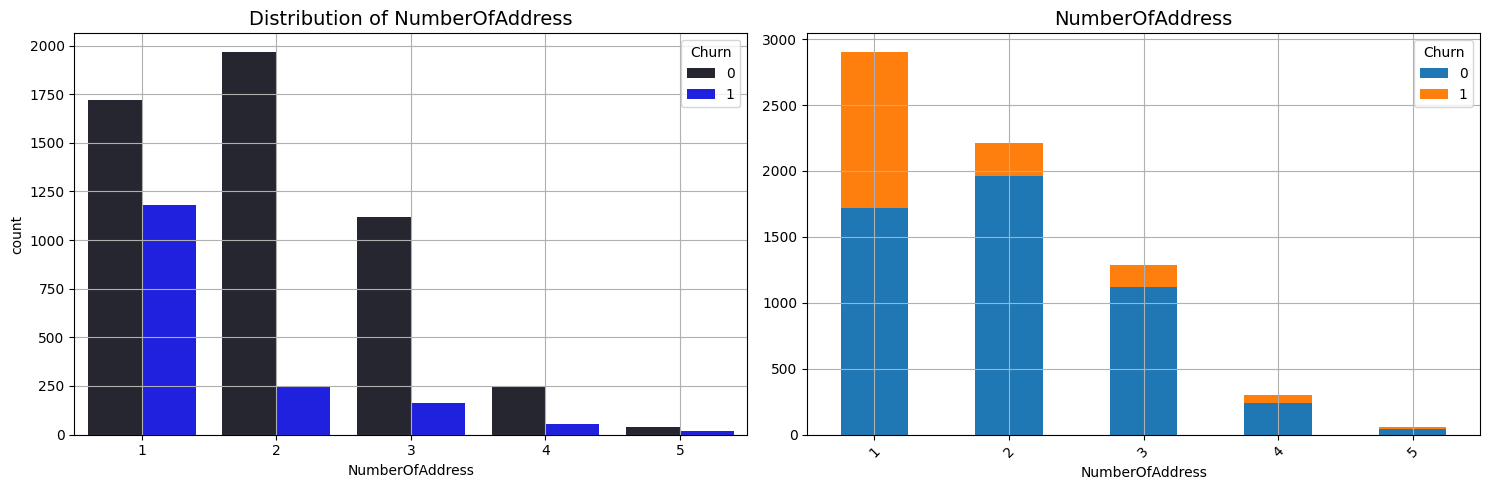

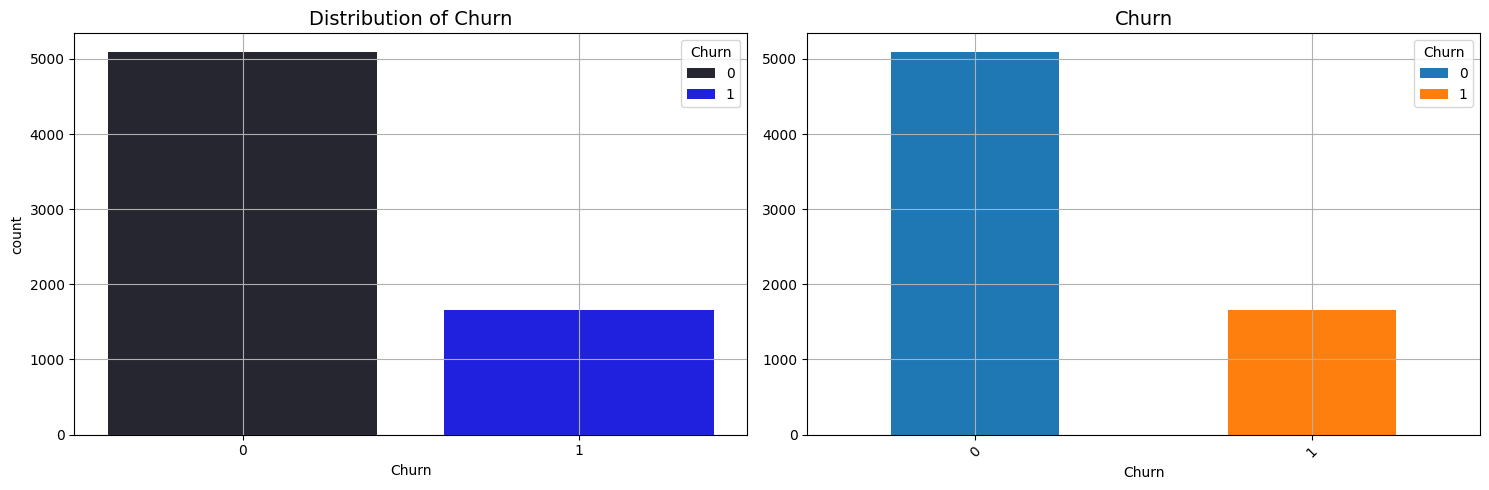

In [30]:
for column in category_features.columns:

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.countplot(data=category_features, x=column, hue="Churn", color="Blue", ax=axes[0])
    axes[0].set_title(f'Distribution of {column}', fontsize=14)
    axes[0].grid()
    
    df_plot = pd.crosstab(category_features[column], category_features["Churn"])
    df_plot.plot(kind='bar', stacked=True, ax=plt.gca())
    plt.title(column, fontsize=14)
    plt.xlabel(column)
    plt.xticks(rotation=45)
    plt.grid()
    
    plt.tight_layout()
    plt.show()

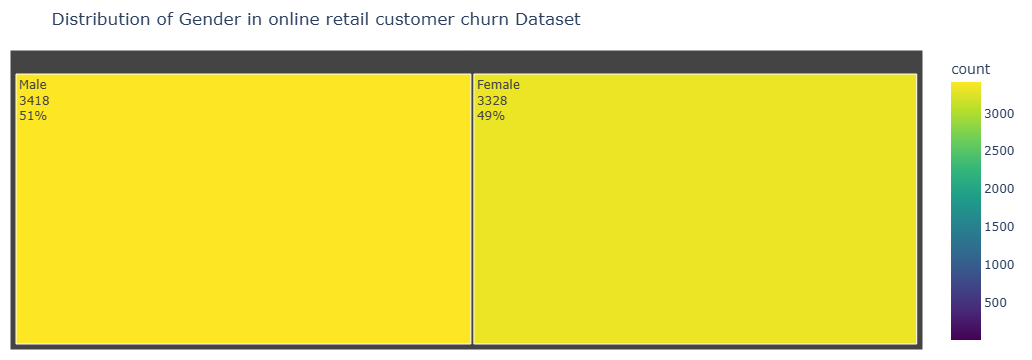

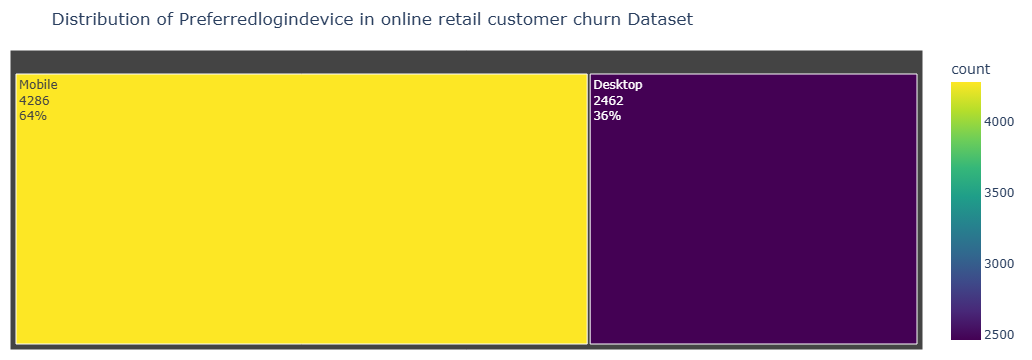

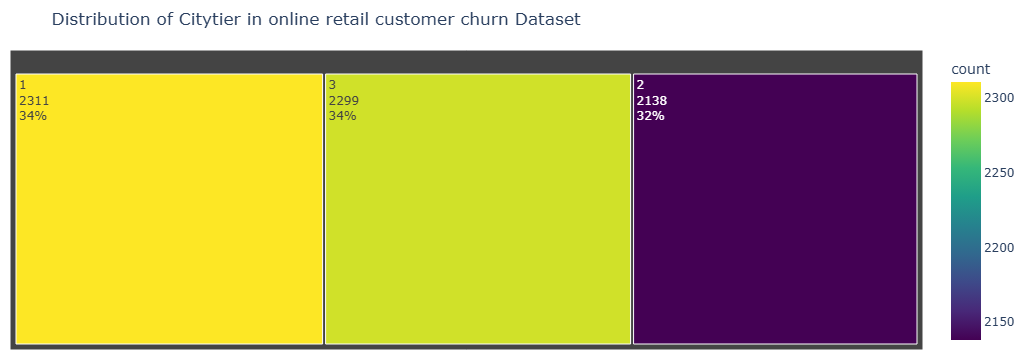

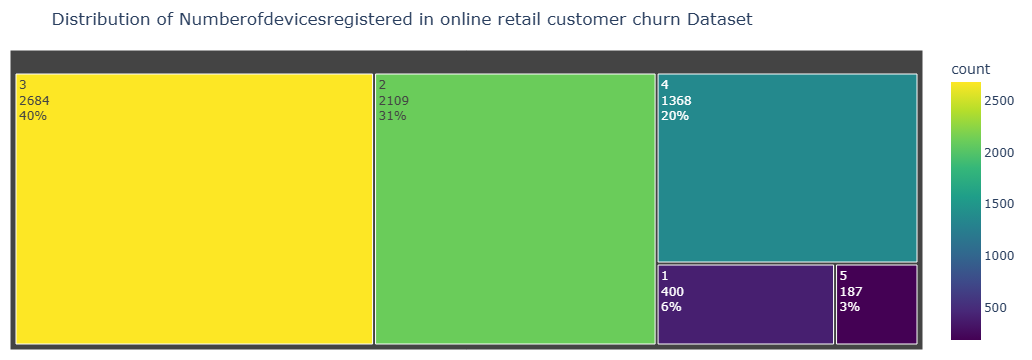

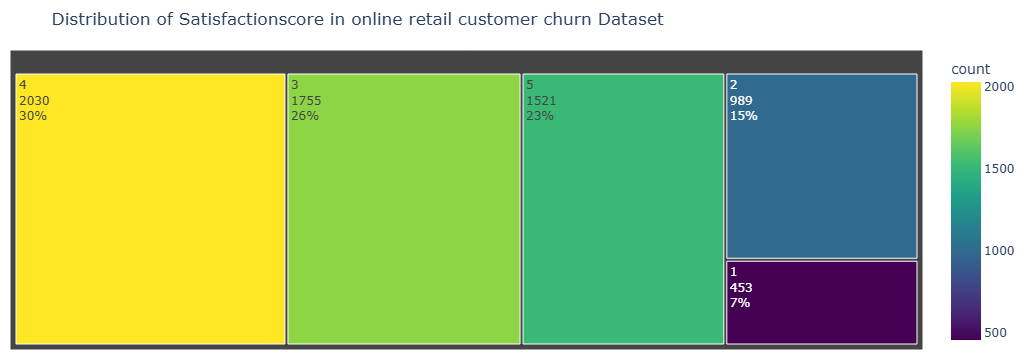

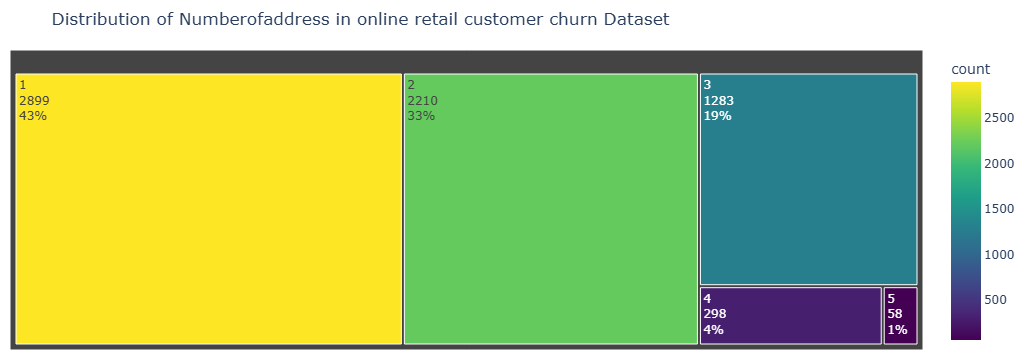

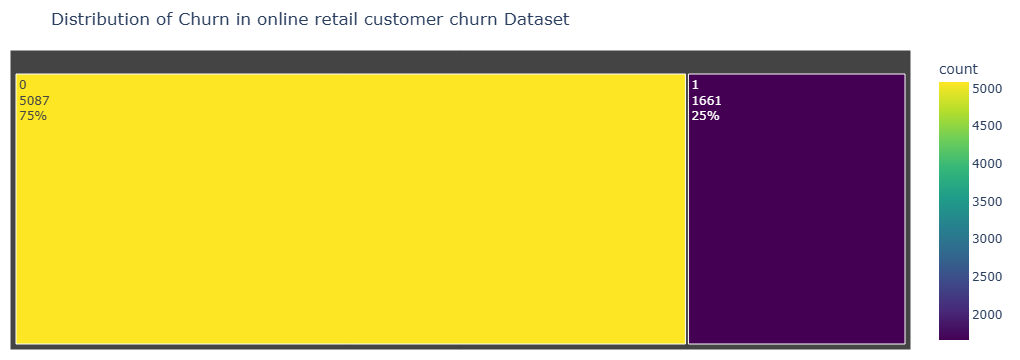

In [31]:
for column in category_features:
    df_counts = category_features[column].value_counts().reset_index()
    
    df_counts.columns = [column, 'count']
    
    fig = px.treemap(df_counts, 
                     path=[column], 
                     values='count',
                     color='count',
                     color_continuous_scale='Viridis',
                     title=f'Distribution of {column.capitalize()} in online retail customer churn Dataset')
    
    fig.update_traces(textinfo="label+value+percent parent")
    fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))
    
    fig.show()

## Target Analysis

In [32]:
(df_customers["Churn"].value_counts() / len(df_customers)) * 100

Churn
0    75.385299
1    24.614701
Name: count, dtype: float64

In [33]:
y = df_customers["Churn"].astype(int).values.reshape(-1)

In [34]:
X = df_customers.drop(columns="Churn")

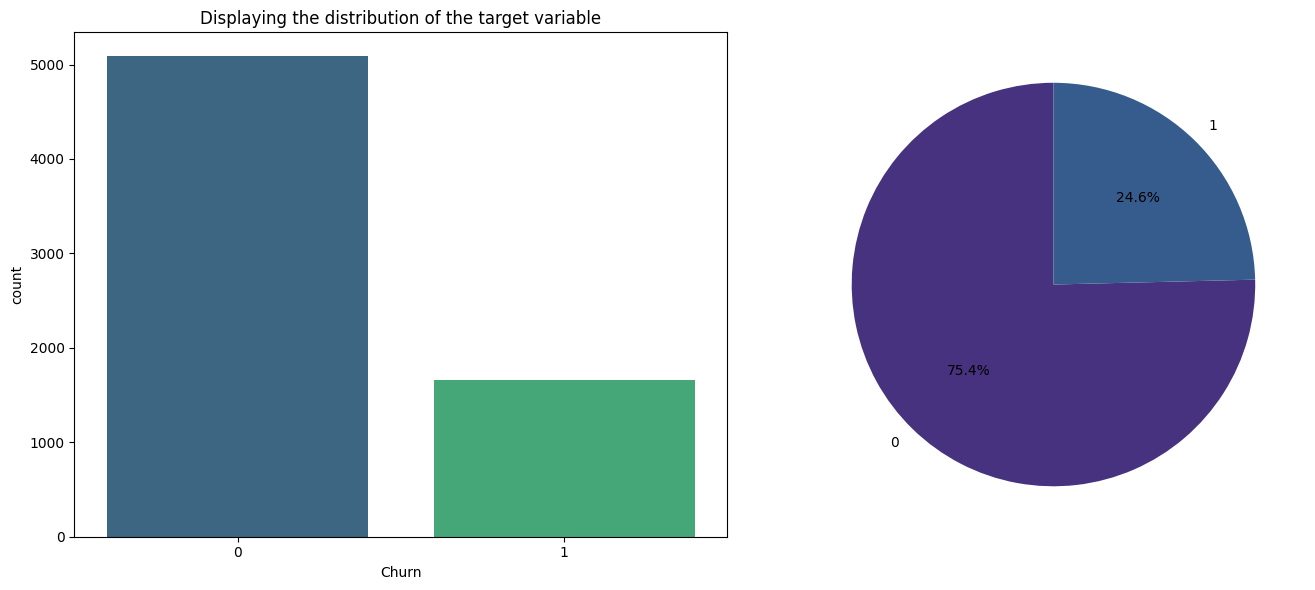

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.countplot(data=df_customers, x="Churn", ax=axes[0], palette="viridis")
axes[0].set_title("Displaying the distribution of the target variable")

counts = df_customers["Churn"].value_counts()
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("viridis"))

plt.tight_layout()
plt.show()

In [36]:
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,  roc_auc_score, roc_curve, auc, classification_report, confusion_matrix

## Preprocessing Pipeline
- **MissingValue :** SimpleImputer
- **Feature egineering :** StandardScaler & OneHotEncoder

In [37]:
numeric_transform = Pipeline(steps=[
    ("MissingValue", SimpleImputer(strategy="median")),
    ("StandardScaler", StandardScaler()),
])

In [38]:
category_transform = Pipeline(steps=[
    ("MissingValue", SimpleImputer(strategy="most_frequent")),
    ("OneHotEncoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

In [39]:
numeric_list = list(X.select_dtypes(["int64", "float64"]).columns)
category_list = list(X.select_dtypes("object").columns)

In [40]:
preprocessor = ColumnTransformer(transformers=[
    ("num_transform", numeric_transform, numeric_list),
    ("cat_transform", category_transform, category_list)
])

## Cross validation

In [41]:
pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature selection", SelectFromModel(LogisticRegression())),
    ("Over Sampling", SMOTE(random_state=1234)),
    ("classifier", LogisticRegression()),
])

stratify_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

cross_validation = cross_validate(estimator=pipeline, X=X, y=y, verbose=10, cv=stratify_fold, scoring=["accuracy", "precision", "recall", "f1"])

[CV] START .....................................................................
[CV] END  accuracy: (test=0.923) f1: (test=0.848) precision: (test=0.826) recall: (test=0.871) total time=   0.1s
[CV] START .....................................................................


[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:    0.1s


[CV] END  accuracy: (test=0.915) f1: (test=0.828) precision: (test=0.824) recall: (test=0.831) total time=   0.0s
[CV] START .....................................................................
[CV] END  accuracy: (test=0.913) f1: (test=0.830) precision: (test=0.801) recall: (test=0.861) total time=   0.0s
[CV] START .....................................................................
[CV] END  accuracy: (test=0.923) f1: (test=0.848) precision: (test=0.824) recall: (test=0.873) total time=   0.1s
[CV] START .....................................................................
[CV] END  accuracy: (test=0.909) f1: (test=0.827) precision: (test=0.777) recall: (test=0.883) total time=   0.0s


[Parallel(n_jobs=1)]: Done   4 tasks      | elapsed:    0.5s
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.6s finished


## Machine learning pipeline
- **Processes :** Missing Value, Scaling, encoding
- **Feature_selection :** feature_selection
- **Over Sampling :** SMOTE
## Modeling
- Logistic Regression
- Random Forest
- SVM
- XGBoost
- LightGBM
## Evaluation
- Accuracy
- Precision
- Recall
- F1
- ROC & AUC

In [42]:
pipelines = {
        "LRC": ImbPipeline(steps=[
            ("Preprocessor", preprocessor),
            ("Feature_Selection", SelectFromModel(LogisticRegression(random_state=1234))),
            ("Over_Sampling", SMOTE(random_state=1234)),
            ("Classifier", LogisticRegression(max_iter=1000, random_state=1234))
        ]),

        "RFC": ImbPipeline(steps=[
            ("Preprocessor", preprocessor),
            ("Feature_Selection", SelectFromModel(LogisticRegression(random_state=1234))),
            ("Over_Sampling", SMOTE(random_state=1234)),
            ("Classifier", RandomForestClassifier(max_depth=5, max_features=4, random_state=1234, ))
        ]),

        "SVM": ImbPipeline(steps=[
            ("Preprocessor", preprocessor),
            ("Feature_selection", SelectFromModel(LogisticRegression(random_state=1234))),
            ("Over Sampling", SMOTE(random_state=1234)),
            ("Classifier", SVC(probability=True, random_state=1234))
        ]),

        "XGBoost": ImbPipeline(steps=[
            ("Preprocessor", preprocessor),
            ("Feature_selection", SelectFromModel(LogisticRegression(random_state=1234))),
            ("Over Sampling", SMOTE(random_state=1234)),
            ("Classifier", XGBClassifier(max_depth=5 ,n_estimators=90, learning_rate=0.1, reg_lambda=0.8, random_state=1234))
        ]),

        "LightGBM": ImbPipeline(steps=[
            ("Preprocessor", preprocessor),
            ("Feature_selection", SelectFromModel(LogisticRegression(random_state=1234))),
            ("Over Sampling", SMOTE(random_state=1234)),
            ("Classifier", LGBMClassifier(max_depth=7, min_data_in_leaf=3, min_gain_to_split=0.8, random_state=1234))
        ]),
}

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1234)

In [44]:
result_train = {}
result_test = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_predict_train = pipe.predict(X_train)
    y_predict_test = pipe.predict(X_test)

    y_proba_train = pipe.predict_proba(X_train)[:, 1]
    y_proba_test = pipe.predict_proba(X_test)[:, 1]

    result_train[name] = {
        "accuracy_train": accuracy_score(y_train, y_predict_train),
        "precision_train": precision_score(y_train, y_predict_train),
        "recall_train": recall_score(y_train, y_predict_train),
        "f1_train": f1_score(y_train, y_predict_train),
        "auc_train": roc_auc_score(y_train, y_proba_train),
    }

    result_test[name] = {
        "accuracy_test": accuracy_score(y_test, y_predict_test),
        "precision_test": precision_score(y_test, y_predict_test),
        "recall_test": recall_score(y_test, y_predict_test),
        "f1_test": f1_score(y_test, y_predict_test),
        "auc_test": roc_auc_score(y_test, y_proba_test),
    }

[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8
[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8
[LightGBM] [Info] Number of positive: 3560, number of negative: 3560
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000979 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 511
[LightGBM] [Info] Number of data points in the train set: 7120, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Wa

In [45]:
results_train = pd.DataFrame(result_train).T
results_test = pd.DataFrame(result_test).T

In [46]:
results_train

,accuracy_train,precision_train,recall_train,f1_train,auc_train
LRC,0.917214,0.803459,0.878762,0.839425,0.969849
RFC,0.931823,0.834527,0.901978,0.866942,0.979534
SVM,0.919966,0.795780,0.907997,0.848193,0.958607
XGBoost,0.941139,0.847604,0.927773,0.885878,0.985289
LightGBM,0.947279,0.864434,0.932072,0.896980,0.987810


In [47]:
results_test

,accuracy_test,precision_test,recall_test,f1_test,auc_test
LRC,0.911605,0.782301,0.887550,0.831609,0.968540
RFC,0.920000,0.805455,0.889558,0.845420,0.973064
SVM,0.913086,0.775685,0.909639,0.837338,0.954452
XGBoost,0.922469,0.809437,0.895582,0.850334,0.974701
LightGBM,0.923457,0.814679,0.891566,0.851390,0.975939


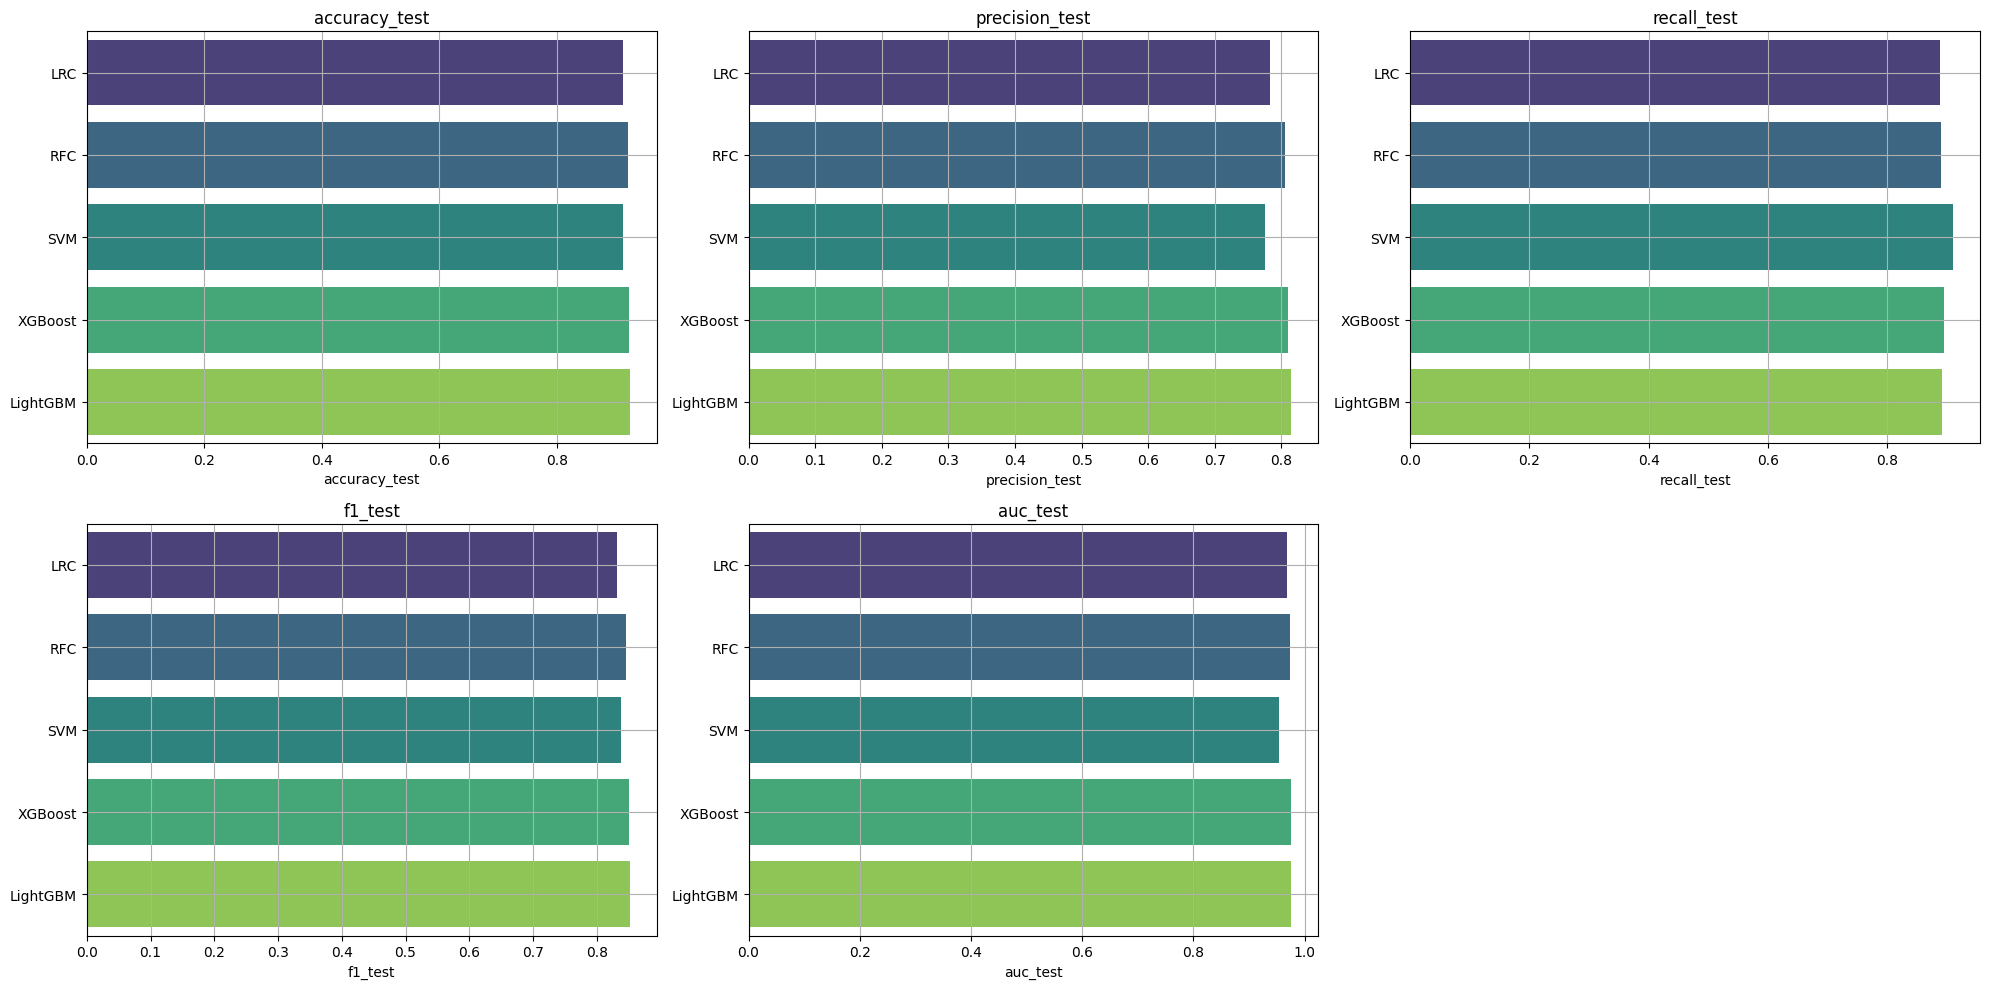

In [48]:
n_cols = 3
n_rows = (len(results_test) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

for i, column in enumerate(results_test):
    sns.barplot(results_test[column], ax=axes[i], palette="viridis", orient='h')
    axes[i].grid()
    axes[i].set_title(column)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Final modeling
- **Best selected model :** lightGBM

In [49]:
pipeline_LGBM = ImbPipeline(steps=[
    ("Preprocess", preprocessor),
    ("feature_selection", SelectFromModel(LogisticRegression(random_state=1234))),
    ("Over Sampling", SMOTE(random_state=1234)),
    ("classifier", LGBMClassifier(max_depth=7, min_data_in_leaf=3, min_gain_to_split=0.8, random_state=1234))
])

In [50]:
pipeline_LGBM.fit(X_train, y_train)

[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8
[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8
[LightGBM] [Info] Number of positive: 3560, number of negative: 3560
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000849 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 511
[LightGBM] [Info] Number of data points in the train set: 7120, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Wa

,steps,"[('Preprocess', ...), ('feature_selection', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](13,)","['Age','Gender','Tenure',...,'OrderCount','DaySinceLastOrder', 'CashbackAmount']"
n_features_in_,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_transform', ...), ('cat_transform', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [51]:
y_pred_train = pipeline_LGBM.predict(X_train)

[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8


In [52]:
print(classification_report(y_pred_train, y_train))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96      3469
           1       0.93      0.86      0.90      1254

    accuracy                           0.95      4723
   macro avg       0.94      0.92      0.93      4723
weighted avg       0.95      0.95      0.95      4723



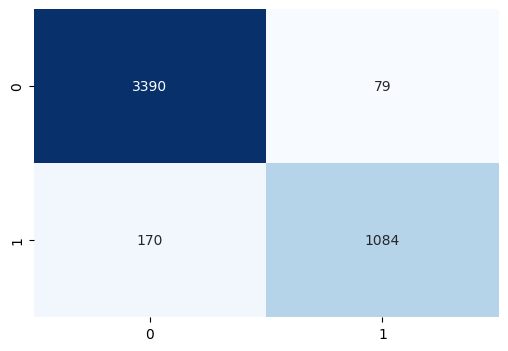

In [53]:
cm_train = confusion_matrix(y_pred_train, y_train)
plt.figure(figsize=(6, 4))

sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.show()

In [54]:
y_pred_test = pipeline_LGBM.predict(X_test)

[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8


In [55]:
print(classification_report(y_pred_test, y_test))

              precision    recall  f1-score   support

           0       0.93      0.96      0.95      1480
           1       0.89      0.81      0.85       545

    accuracy                           0.92      2025
   macro avg       0.91      0.89      0.90      2025
weighted avg       0.92      0.92      0.92      2025



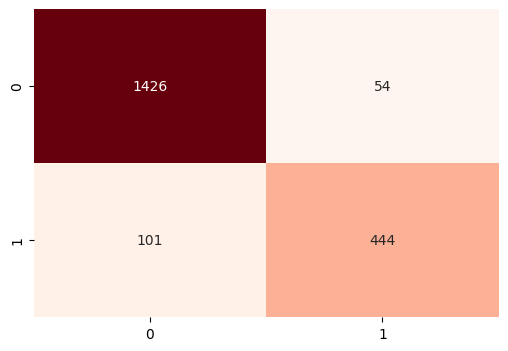

In [56]:
cm_test = confusion_matrix(y_pred_test, y_test)
plt.figure(figsize=(6, 4))

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Reds', cbar=False)
plt.show()

In [57]:
y_proba_test = pipeline_LGBM.predict_proba(X_test)[:, 1]

[LightGBM] [Warning] min_data_in_leaf is set=3, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=3
[LightGBM] [Warning] min_gain_to_split is set=0.8, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.8


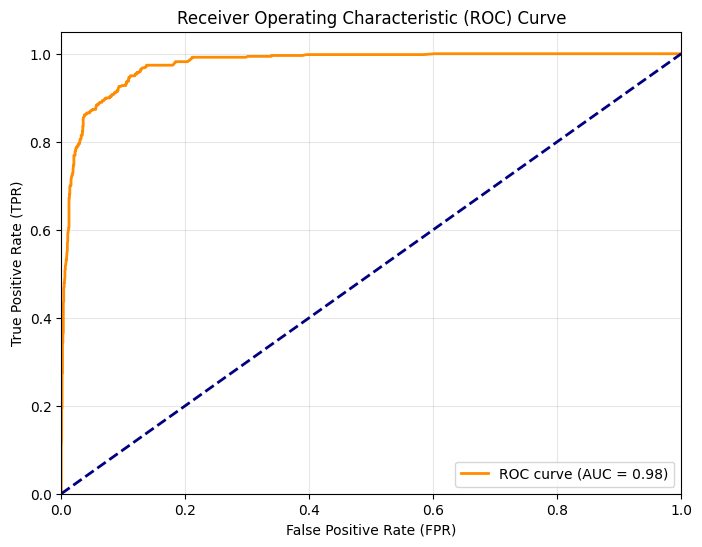

In [58]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_test)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # خط مورب برای مدل تصادفی
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

Found 2 transformer steps. Applying them...


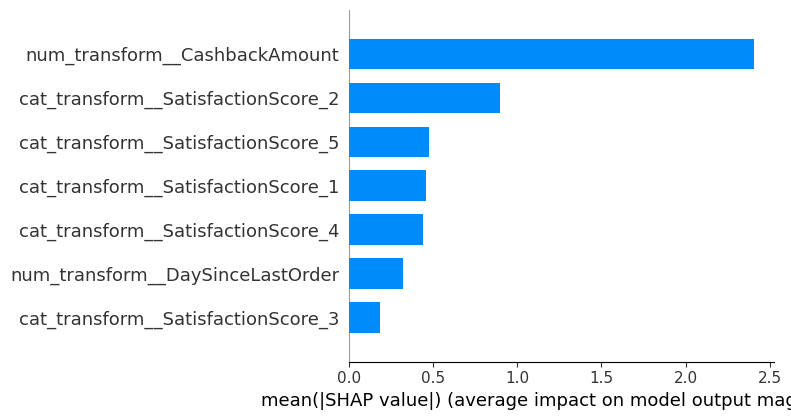

In [59]:
import pandas as pd
import shap
from sklearn.base import TransformerMixin, BaseEstimator

transformers_only = []

for name, step in pipeline_LGBM.steps:
    
    if name == 'Classifier': 
        break
    
    if hasattr(step, 'transform'):

        from imblearn.over_sampling import SMOTE
        if not isinstance(step, SMOTE):
            transformers_only.append(step)

print(f"Found {len(transformers_only)} transformer steps. Applying them...")

X_test_transformed = X_test.copy()

for transformer in transformers_only:
    
    X_test_transformed = transformer.transform(X_test_transformed)

try:
    
    current_cols = X_test.columns
    for transformer in transformers_only:
        if hasattr(transformer, 'get_feature_names_out'):
            current_cols = transformer.get_feature_names_out(current_cols)
    X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=current_cols)
except Exception as e:
    print(f"Column naming failed, using default indices. Error: {e}")
    X_test_transformed_df = pd.DataFrame(X_test_transformed)

model_step = pipeline_LGBM.named_steps["classifier"]
explainer = shap.TreeExplainer(model_step)
shap_values = explainer.shap_values(X_test_transformed_df)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar")